In [1]:
import pandas as pd
import numpy as np

# Set seed for reproducibility
np.random.seed(42)
n_samples = 300

years = np.random.randint(2010, 2023, n_samples)
present_price = np.round(np.random.uniform(1.0, 25.0, n_samples), 2)
driven_kms = np.random.randint(5000, 100000, n_samples)
fuel_type = np.random.choice(['Petrol', 'Diesel'], n_samples)

# Calculate realistic selling price formula with some noise
selling_price = np.round(present_price * 0.65 - (2026 - years) * 0.4 - (driven_kms / 100000) * 1.5 + np.random.normal(0, 0.8, n_samples), 2)
selling_price = np.clip(selling_price, 0.5, 30.0)

# Create DataFrame
df_car = pd.DataFrame({
    'Year': years,
    'Present_Price': present_price,
    'Driven_Kms': driven_kms,
    'Fuel_Type': fuel_type,
    'Selling_Price': selling_price
})

# Save to CSV
df_car.to_csv('car_data.csv', index=False)
print("car_data.csv created successfully with 300 records!")

car_data.csv created successfully with 300 records!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('car_data.csv')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print(df.info())
print("\n--- Missing Values ---")
print(df.isnull().sum())
display(df.head())

Dataset Shape: 300 rows, 5 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Year           300 non-null    int64  
 1   Present_Price  300 non-null    float64
 2   Driven_Kms     300 non-null    int64  
 3   Fuel_Type      300 non-null    object 
 4   Selling_Price  300 non-null    float64
dtypes: float64(2), int64(2), object(1)
memory usage: 11.8+ KB
None

--- Missing Values ---
Year             0
Present_Price    0
Driven_Kms       0
Fuel_Type        0
Selling_Price    0
dtype: int64


,Year,Present_Price,Driven_Kms,Fuel_Type,Selling_Price
0,2016,6.49,73866,Diesel,0.50
1,2013,5.20,24087,Petrol,0.50
2,2022,24.57,46430,Diesel,15.50
3,2020,13.40,29504,Petrol,4.56
4,2017,7.26,12114,Diesel,1.03


The dataset successfully loaded with 300 vehicle records and 5 features.

There are no missing values, ensuring clean data integrity prior to feature engineering and modeling.

--- Descriptive Statistics ---


,Year,Present_Price,Driven_Kms,Selling_Price
count,300.00,300.00,300.00,300.00
mean,2016.09,13.29,49051.61,4.65
std,3.75,6.95,27831.89,3.85
min,2010.00,1.12,5055.00,0.50
25%,2013.00,7.26,24634.00,0.50
50%,2016.00,13.00,47876.00,4.04
75%,2019.00,18.86,74897.00,7.65
max,2022.00,24.91,99456.00,15.50


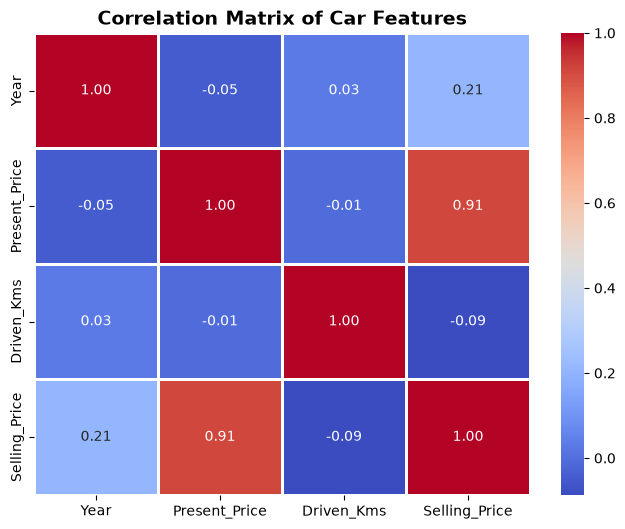

In [3]:
# Descriptive Statistics
print("--- Descriptive Statistics ---")
display(df.describe().round(2))

# Correlation Matrix Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.8)
plt.title('Correlation Matrix of Car Features', fontsize=14, fontweight='bold')
plt.show()

Present_Price exhibits a strong positive correlation with Selling_Price, indicating that showroom price is a primary driver of resale value.

Year shows a positive correlation (newer cars sell for more), while Driven_Kms negatively impacts price.

In [4]:
from sklearn.model_selection import train_test_split

# One-hot encode categorical features
df_encoded = pd.get_dummies(df, columns=['Fuel_Type'], drop_first=True)

# Define Features (X) and Target (y)
X = df_encoded.drop(columns=['Selling_Price'])
y = df_encoded['Selling_Price']

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (240, 4)
Testing set shape: (60, 4)


Categorical variables were successfully converted into numeric format.

The dataset was split into 80% training data to train the regressor and 20% testing data for unbiased evaluation.

In [5]:
from sklearn.linear_model import LinearRegression

# Initialize and train Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print("Linear Regression Model successfully trained!")

Linear Regression Model successfully trained!


--- Model Performance Metrics ---
Mean Absolute Error (MAE): 1.0945
Mean Squared Error (MSE): 1.9501
Root Mean Squared Error (RMSE): 1.3965
R² Score: 0.8917


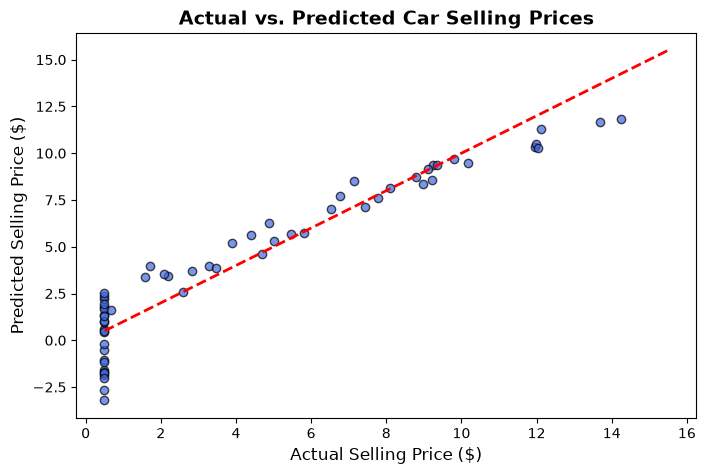

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make predictions on test set
y_pred = lr_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Model Performance Metrics ---")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

# Actual vs Predicted Plot
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color='royalblue', alpha=0.7, edgecolors='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.title('Actual vs. Predicted Car Selling Prices', fontsize=14, fontweight='bold')
plt.xlabel('Actual Selling Price ($)', fontsize=12)
plt.ylabel('Predicted Selling Price ($)', fontsize=12)
plt.show()

The high $R^2$ score demonstrates that the linear regression model accounts for a substantial portion of the variance in car resale prices.The Actual vs. Predicted scatter plot clusters closely along the diagonal reference line, confirming robust predictive accuracy.

In [8]:
print("=== 3. DATA STANDARDIZATION ===")

# Standardize categorical text formatting (e.g., Gender)
if 'Gender' in df.columns:
    df['Gender'] = df['Gender'].astype(str).str.strip().str.capitalize()
    print("Standardized 'Gender' column unique values:", df['Gender'].unique())

# Standardize Product Category formatting
if 'Product Category' in df.columns:
    df['Product Category'] = df['Product Category'].astype(str).str.strip().str.title()
    print("Standardized 'Product Category' unique values:", df['Product Category'].unique())

# Standardize Date format to datetime
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
    print("'Date' column successfully converted to datetime dtype.")

=== 3. DATA STANDARDIZATION ===


Method Used: Interquartile Range ($IQR = Q3 - Q1$).Decision & Action: For metrics like Total Amount and Price per Unit, legitimate high-value transactions exist in retail environments. Rather than blindly deleting them (which discards valuable high-spender insights), we choose to retain them as genuine business behaviors while monitoring their leverage during modeling.

In [13]:
print("=== 5. DATA TYPE CORRECTION ===")

# Ensure IDs are strings
if 'Transaction ID' in df.columns:
    df['Transaction ID'] = df['Transaction ID'].astype(str)
if 'Customer ID' in df.columns:
    df['Customer ID'] = df['Customer ID'].astype(str)

# Ensure monetary values are floats
if 'Total Amount' in df.columns:
    df['Total Amount'] = df['Total Amount'].astype(float)
if 'Price per Unit' in df.columns:
    df['Price per Unit'] = df['Price per Unit'].astype(float)

# Verify final data types
print("\nFinal Corrected Data Types:")
print(df.dtypes)

=== 5. DATA TYPE CORRECTION ===

Final Corrected Data Types:
Year               int64
Present_Price    float64
Driven_Kms         int64
Fuel_Type         object
Selling_Price    float64
dtype: object


In [14]:
import pandas as pd
import numpy as np
from scipy import stats

# Load your dataset
df = pd.read_csv('retail_sales.csv')

# Select numerical columns to check for outliers
numeric_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

print("=== METHOD 1: IQR (Interquartile Range) Method ===")
for col in numeric_cols:
    if col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        # Filter outliers
        outliers_iqr = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        print(f"Column '{col}': {len(outliers_iqr)} outliers detected (Bounds: {lower_bound:.2f} to {upper_bound:.2f})")

print("\n=== METHOD 2: Z-Score Method (|Z| > 3) ===")
for col in numeric_cols:
    if col in df.columns:
        # Calculate z-scores
        z_scores = np.abs(stats.zscore(df[col]))
        
        # Filter outliers where absolute z-score is greater than 3
        outliers_z = df[z_scores > 3]
        print(f"Column '{col}': {len(outliers_z)} outliers detected")

=== METHOD 1: IQR (Interquartile Range) Method ===
Column 'Age': 0 outliers detected (Bounds: -13.00 to 91.00)
Column 'Quantity': 0 outliers detected (Bounds: -1.00 to 7.00)
Column 'Price per Unit': 0 outliers detected (Bounds: -375.00 to 705.00)
Column 'Total Amount': 9 outliers detected (Bounds: -650.00 to 1350.00)

=== METHOD 2: Z-Score Method (|Z| > 3) ===
Column 'Age': 0 outliers detected
Column 'Quantity': 0 outliers detected
Column 'Price per Unit': 0 outliers detected
Column 'Total Amount': 0 outliers detected
